<a href="https://colab.research.google.com/github/asyatahir/math3/blob/main/Math3_COVID_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**EXTRACT FILE**

In [ ]:
# Upload CSV
from google.colab import files
uploaded = files.upload()

Saving cases_malaysia.csv to cases_malaysia.csv


In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12,5)

In [ ]:
# Load Dataset
df = pd.read_csv('cases_malaysia.csv')

df.head()

# Check Columns
print(df.columns)

Index(['date', 'cases_new', 'cases_import', 'cases_recovered', 'cases_active',
       'cases_cluster', 'cases_unvax', 'cases_pvax', 'cases_fvax',
       'cases_boost', 'cases_child', 'cases_adolescent', 'cases_adult',
       'cases_elderly', 'cases_0_4', 'cases_5_11', 'cases_12_17',
       'cases_18_29', 'cases_30_39', 'cases_40_49', 'cases_50_59',
       'cases_60_69', 'cases_70_79', 'cases_80', 'cluster_import',
       'cluster_religious', 'cluster_community', 'cluster_highRisk',
       'cluster_education', 'cluster_detentionCentre', 'cluster_workplace'],
      dtype='object')


In [ ]:
# Convert Date and Filter Year (2021)
df['date'] = pd.to_datetime(df['date'])

df_2021 = df[
    (df['date'] >= '2021-01-01') &
    (df['date'] <= '2021-12-31')
].copy()

print("Total records:", len(df_2021))
df_2021.head()

Total records: 365


,date,cases_new,cases_import,cases_recovered,cases_active,cases_cluster,cases_unvax,cases_pvax,cases_fvax,cases_boost,...,cases_60_69,cases_70_79,cases_80,cluster_import,cluster_religious,cluster_community,cluster_highRisk,cluster_education,cluster_detentionCentre,cluster_workplace
342,2021-01-01,2068,2,2230,23434,944,2068,0,0,0,...,72,36,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
343,2021-01-02,2295,9,3321,22399,1091,2295,0,0,0,...,89,19,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
344,2021-01-03,1704,5,2726,21366,588,1704,0,0,0,...,79,26,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
345,2021-01-04,1741,8,1010,22090,618,1741,0,0,0,...,71,23,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
346,2021-01-05,2027,16,1221,22885,776,2027,0,0,0,...,80,36,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Statistics
print(df_2021['cases_new'].describe())

count      365.000000
mean      7246.783562
std       6014.240082
min        941.000000
25%       3100.000000
50%       5218.000000
75%       8817.000000
max      24599.000000
Name: cases_new, dtype: float64


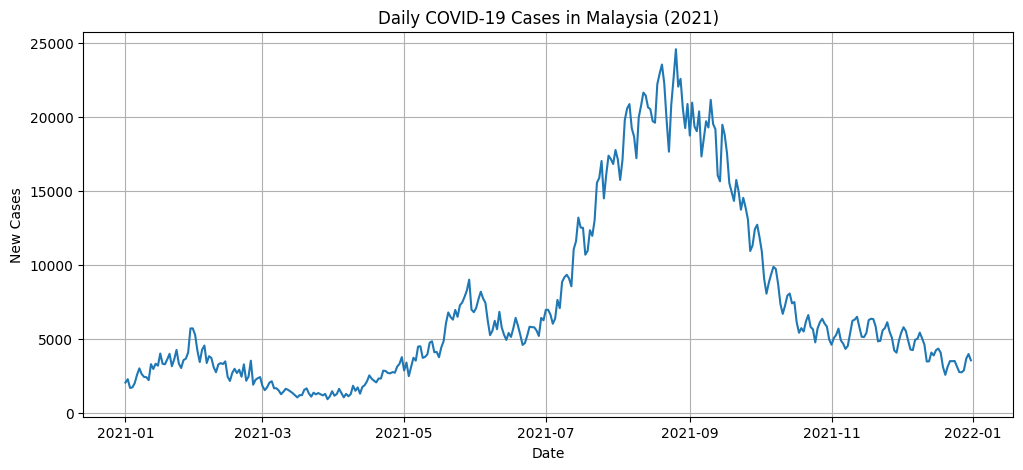

In [ ]:
# Visualize Daily Case
plt.plot(df_2021['date'], df_2021['cases_new'])

plt.title('Daily COVID-19 Cases in Malaysia (2021)')
plt.xlabel('Date')
plt.ylabel('New Cases')
plt.grid(True)

plt.show()

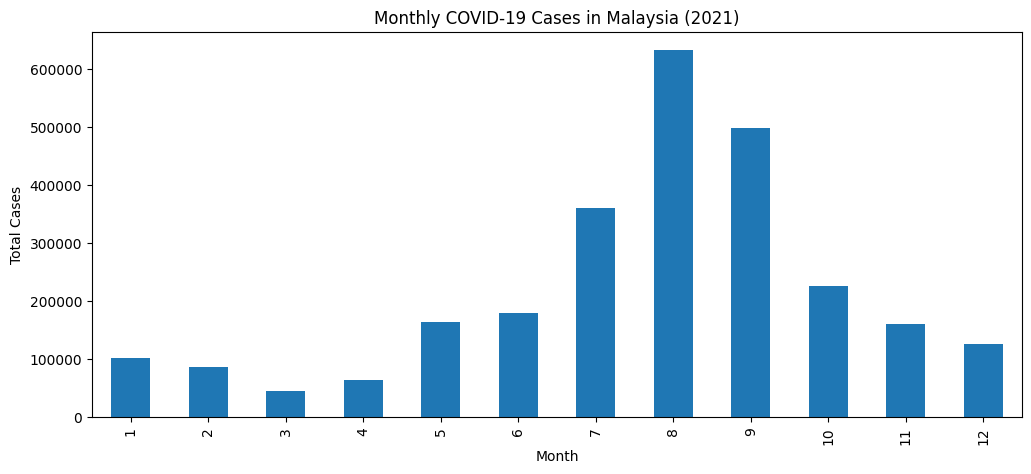

In [ ]:
# Monthly Summary
monthly_cases = df_2021.groupby(
    df_2021['date'].dt.month
)['cases_new'].sum()

monthly_cases

# Monthly Cases Graph
monthly_cases.plot(kind='bar')

plt.title('Monthly COVID-19 Cases in Malaysia (2021)')
plt.xlabel('Month')
plt.ylabel('Total Cases')

plt.show()

**MARKOV CHAIN**

state
Low       175
Medium    132
High       58
Name: count, dtype: int64


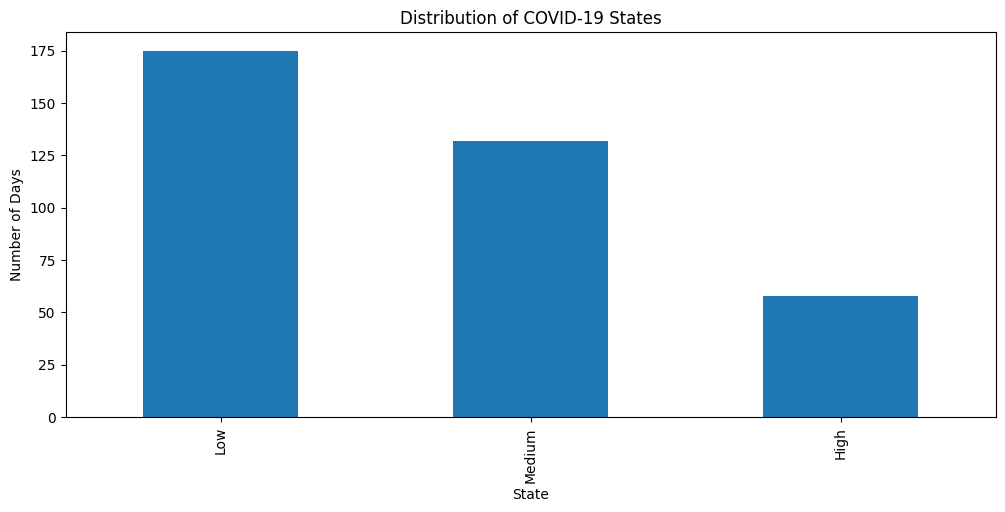

In [ ]:
# Classify States
def classify_cases(cases):

    if cases < 5000:
        return 'Low'

    elif cases < 15000:
        return 'Medium'

    else:
        return 'High'

df_2021['state'] = df_2021['cases_new'].apply(classify_cases)

df_2021[['date','cases_new','state']].head(20)

# State Distribution
df_2021['state'].value_counts()
print(df_2021['state'].value_counts())

# Visualize State Distribution
df_2021['state'].value_counts().plot(kind='bar')

plt.title('Distribution of COVID-19 States')
plt.xlabel('State')
plt.ylabel('Number of Days')

plt.show()

In [ ]:
# Create State Transitions
states = df_2021['state'].tolist()

transitions = []

for i in range(len(states)-1):
    transitions.append((states[i], states[i+1]))

transitions[:10]

[('Low', 'Low'),
 ('Low', 'Low'),
 ('Low', 'Low'),
 ('Low', 'Low'),
 ('Low', 'Low'),
 ('Low', 'Low'),
 ('Low', 'Low'),
 ('Low', 'Low'),
 ('Low', 'Low'),
 ('Low', 'Low')]

In [ ]:
# Count Transitions
transition_counts = pd.DataFrame(
    0,
    index=['Low','Medium','High'],
    columns=['Low','Medium','High']
)

for current_state, next_state in transitions:
    transition_counts.loc[current_state, next_state] += 1

transition_counts

,Low,Medium,High
Low,164,10,0
Medium,10,119,3
High,0,3,55


In [ ]:
# Transition Probability Matrix
transition_matrix = transition_counts.div(
    transition_counts.sum(axis=1),
    axis=0
)

transition_matrix

,Low,Medium,High
Low,0.942529,0.057471,0.000000
Medium,0.075758,0.901515,0.022727
High,0.000000,0.051724,0.948276


In [ ]:
# Predict Next State Probability
current_state = 'Low'

prediction = transition_matrix.loc[current_state]

print(prediction)

Low       0.942529
Medium    0.057471
High      0.000000
Name: Low, dtype: float64


In [ ]:
# Predict Next State
predicted_state = prediction.idxmax()

print("Predicted next state:", predicted_state)

Predicted next state: Low


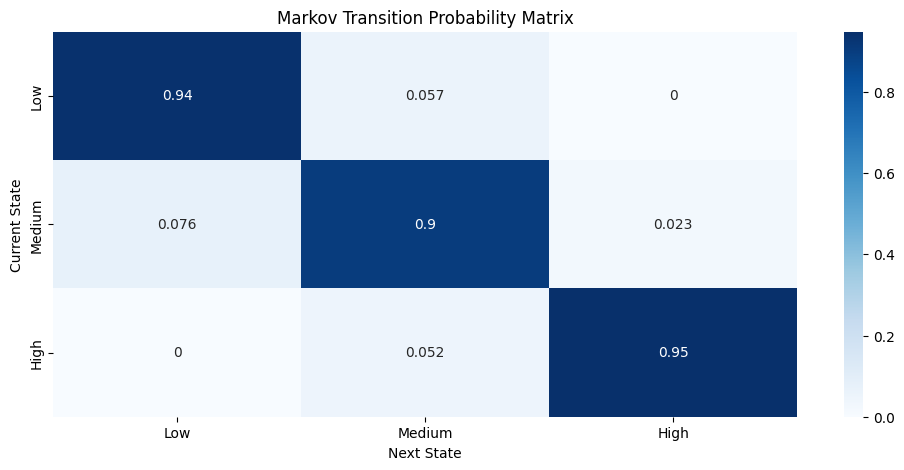

In [ ]:
# Heatmap Transition Matrix
import seaborn as sns

sns.heatmap(
    transition_matrix,
    annot=True,
    cmap='Blues'
)

plt.title('Markov Transition Probability Matrix')
plt.xlabel('Next State')
plt.ylabel('Current State')
plt.show()

In [ ]:
state_mean_cases = df_2021.groupby('state')['cases_new'].mean().to_dict()

predicted_next_states = []
for state in df_2021['state']:
    if state in transition_matrix.index:
        next_state_probs = transition_matrix.loc[state]
        predicted_next_states.append(next_state_probs.idxmax())
    else:
        # Fallback if a state is not in the transition matrix (should not happen with this data)
        predicted_next_states.append(state)

df_eval = pd.DataFrame({
    'predicted_state': predicted_next_states[:-1]
})

df_eval['actual_cases'] = (
    df_2021['cases_new']
    .shift(-1)
    .dropna()
    .values
)

df_eval['predicted_cases'] = (
    df_eval['predicted_state']
    .map(state_mean_cases)
)

df_eval[['actual_cases',
         'predicted_cases']].head()

,actual_cases,predicted_cases
0,2295.0,2930.211429
1,1704.0,2930.211429
2,1741.0,2930.211429
3,2027.0,2930.211429
4,2593.0,2930.211429


In [ ]:
# Evaluation Metrics
from sklearn.metrics import mean_squared_error
import numpy as np

mse_markov = mean_squared_error(
    df_eval['actual_cases'],
    df_eval['predicted_cases']
)

rmse_markov = np.sqrt(mse_markov)

print("Markov Mean Squared Error (MSE):", mse_markov)
print("Markov Root Mean Squared Error (RMSE):", rmse_markov)

Markov Mean Squared Error (MSE): 4398801.28119516
Markov Root Mean Squared Error (RMSE): 2097.3319434927703


In [ ]:
state_mean_cases = df_2021.groupby('state')['cases_new'].mean()

print(state_mean_cases)

state
High      19296.568966
Low        2930.211429
Medium     7674.909091
Name: cases_new, dtype: float64


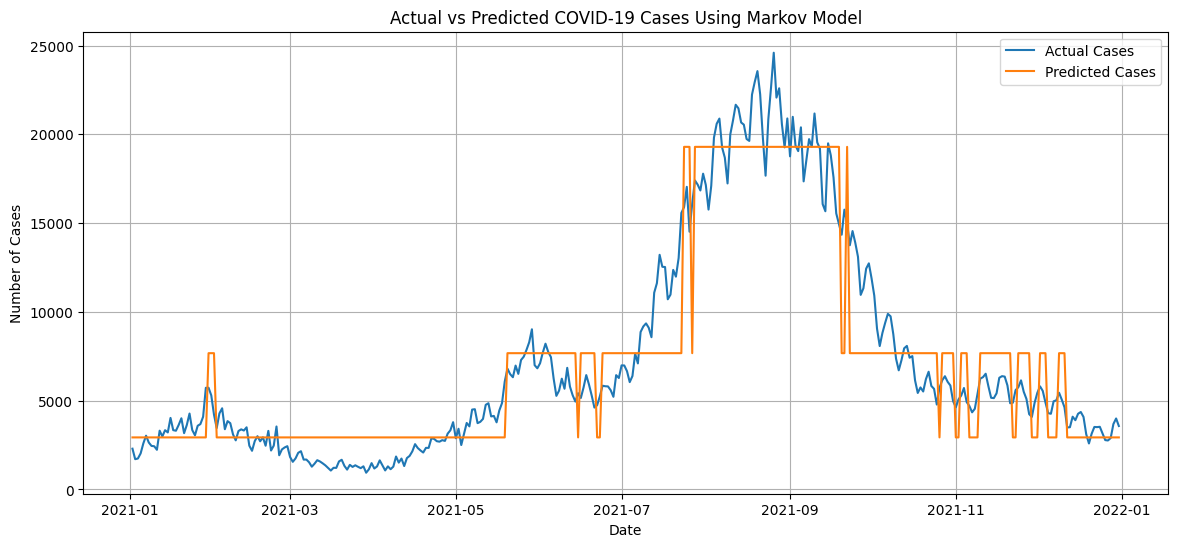

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.plot(
    df_2021['date'].iloc[1:],
    df_eval['actual_cases'],
    label='Actual Cases'
)

plt.plot(
    df_2021['date'].iloc[1:],
    df_eval['predicted_cases'],
    label='Predicted Cases'
)

plt.title('Actual vs Predicted COVID-19 Cases Using Markov Model')
plt.xlabel('Date')
plt.ylabel('Number of Cases')
plt.legend()
plt.grid(True)

plt.show()

**DISCRETE DYNAMIC SYSTEM (DDS)**

In [ ]:
# Select daily COVID cases
cases = df_2021['cases_new'].values

In [ ]:
# Create current day and next day data
x_t = cases[:-1]  #today's cases
x_t1 = cases[1:] #tomorrow's cases


In [ ]:
#Find DDS parameters
# Equation: x(t+1) = a*x(t) + b
a,b = np.polyfit(x_t, x_t1, 1)


In [ ]:
print("Discrete Dynamic System Equation:")
print(f"x(t+1) = {a:.4f} * x(t) + {b:.4f}")

Discrete Dynamic System Equation:
x(t+1) = 0.9887 * x(t) + 86.4397


In [ ]:
# Generate predictions
predicted_cases = a * x_t + b

In [ ]:
print(f"x(t+1) = {a:.4f} * x(t) + {b:.4f}")

x(t+1) = 0.9887 * x(t) + 86.4397


In [ ]:
# Create DDS evaluation table
df_dds_eval = pd.DataFrame({
    'actual_cases': x_t1,
    'predicted_cases': predicted_cases
})

# Show first 5 rows
df_dds_eval[['actual_cases',
             'predicted_cases']].head()

,actual_cases,predicted_cases
0,2295,2130.985099
1,1704,2355.410541
2,1741,1771.113464
3,2027,1807.693822
4,2593,2090.450107


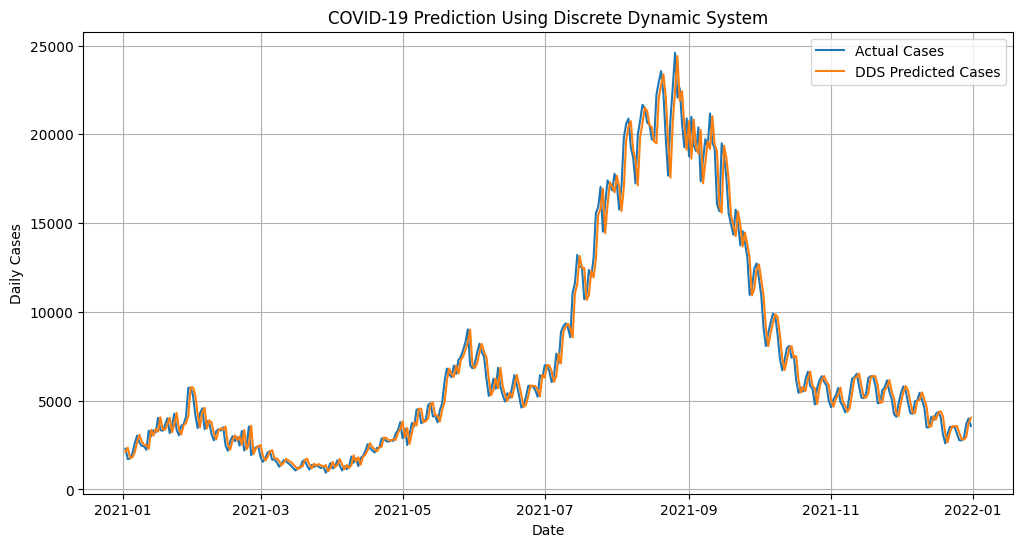

In [ ]:
# Plot actual vs predicted
plt.figure(figsize=(12,6))

plt.plot(df_2021['date'][1:], x_t1,
         label='Actual Cases')

plt.plot(df_2021['date'][1:], predicted_cases,
         label='DDS Predicted Cases')

plt.title('COVID-19 Prediction Using Discrete Dynamic System')
plt.xlabel('Date')
plt.ylabel('Daily Cases')
plt.legend()
plt.grid()

plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Calculate MSE
mse_dds = mean_squared_error(x_t1, predicted_cases)

# Calculate RMSE
rmse_dds = np.sqrt(mse_dds)

print("DDS Mean Squared Error (MSE):", mse_dds)
print("DDS Root Mean Squared Error (RMSE):", rmse_dds)

DDS Mean Squared Error (MSE): 778286.5107879249
DDS Root Mean Squared Error (RMSE): 882.2054810461817


**LEAST SQUARES**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Convert date into day number
df_2021['day_num'] = (df_2021['date'] - df_2021['date'].min()).dt.days

# x = day number, y = daily new cases
x = df_2021['day_num'].values
y = df_2021['cases_new'].values

# Least squares linear regression
slope, intercept = np.polyfit(x, y, 1)

# Predicted cases
df_2021['predicted_cases'] = intercept + slope * x

print("Intercept:", intercept)
print("Slope (average number of days):", slope)

Intercept: 3228.3924096114965
Slope (average number of days): 22.079072263913954


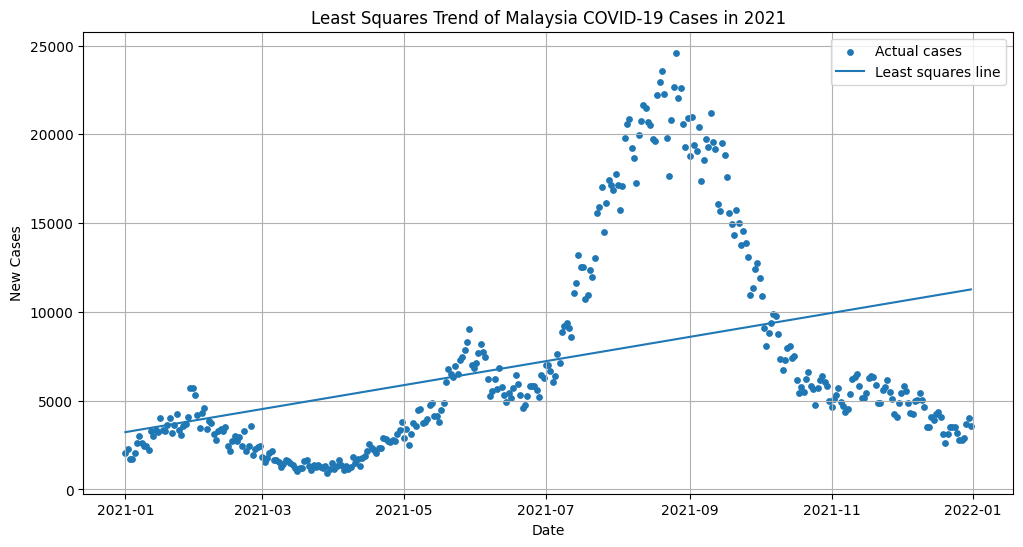

In [ ]:
plt.figure(figsize=(12, 6))

plt.scatter(df_2021['date'], df_2021['cases_new'], label='Actual cases', s=15)
plt.plot(df_2021['date'], df_2021['predicted_cases'], label='Least squares line')

plt.xlabel('Date')
plt.ylabel('New Cases')
plt.title('Least Squares Trend of Malaysia COVID-19 Cases in 2021')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
y_pred = df_2021['predicted_cases'].values

ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)

mse = np.mean((y - y_pred) ** 2)
rmse_ls = np.sqrt(np.mean((y - y_pred) ** 2))

r2 = 1 - (ss_res / ss_tot)

print("Least Square Mean Squared Error (MSE):", mse)
print("Least Square Root Mean Squared Error (RMSE):", rmse_ls)
print("Least Square R-squared (R2):", r2)

Least Square Mean Squared Error (MSE): 30659921.63738531
Least Square Root Mean Squared Error (RMSE): 5537.140203876484
Least Square R-squared (R2): 0.1500350834832498


Quadratic Least Square ***Taknak Guna**

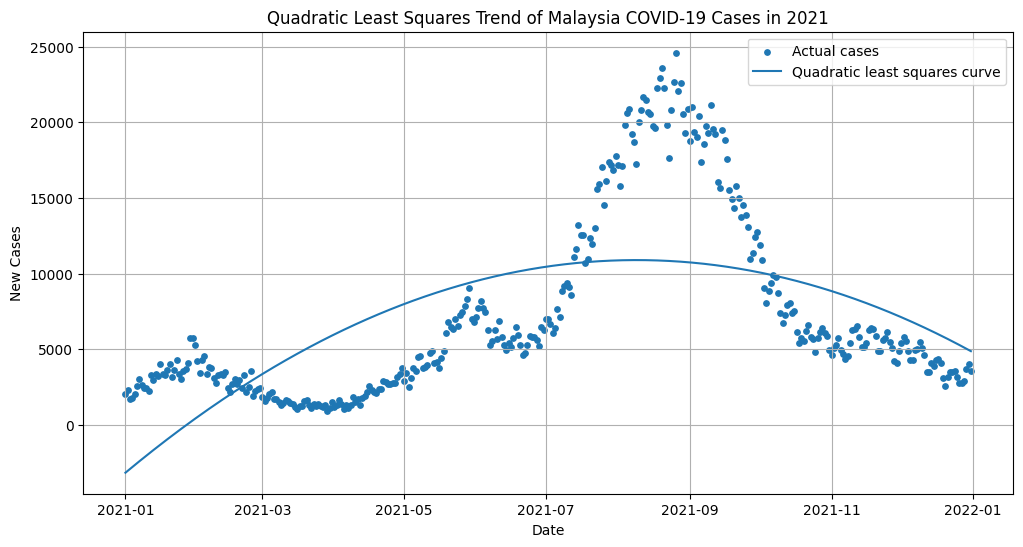

In [ ]:
# Quadratic least squares: y = ax² + bx + c
coefficients = np.polyfit(x, y, 2)

df_2021['quadratic_predicted'] = np.polyval(coefficients, x)

plt.figure(figsize=(12, 6))

plt.scatter(df_2021['date'], df_2021['cases_new'], label='Actual cases', s=15)
plt.plot(df_2021['date'], df_2021['quadratic_predicted'], label='Quadratic least squares curve')

plt.xlabel('Date')
plt.ylabel('New Cases')
plt.title('Quadratic Least Squares Trend of Malaysia COVID-19 Cases in 2021')
plt.legend()
plt.grid(True)
plt.show()